# Yellow Sigatoka Final Test Evaluation

Evaluate the frozen XGBoost model once on the held-out test split. This notebook does not train or tune a model.

## 1. Import Libraries

In [1]:
# Import libraries
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid")


## 2. Load Selected Model

Load the saved XGBoost model and its metadata. No model fitting or updating is performed.

In [2]:
# Load the saved model
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_DIR = PROJECT_ROOT / "Models" / "yellow_sigatoka" / "xgboost"
model_path = MODEL_DIR / "xgboost_model.joblib"
metadata_path = MODEL_DIR / "xgboost_metadata.json"

model = joblib.load(model_path)
with metadata_path.open(encoding="utf-8") as metadata_file:
    model_metadata = json.load(metadata_file)

print("Selected setting:", model_metadata["selected_setting"])
print("Selected parameters:", model_metadata["parameters"])
print("Saved validation metrics:", model_metadata["validation_metrics"])


Selected setting: Model 4
Selected parameters: {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05, 'objective': 'reg:squarederror', 'random_state': 42, 'n_jobs': -1}
Saved validation metrics: {'mae': 0.5009309815569393, 'rmse': 0.7687611496098211, 'r2': 0.9993761686880307, 'risk_level_accuracy': 0.9833333333333333, 'risk_level_macro_f1': 0.9832894720691382}


## 3. Load Test Data

Load the held-out test CSV once for this final evaluation.

In [3]:
# Load the test data
TEST_PATH = PROJECT_ROOT / "datasets" / "yellow_sigatoka" / "YS_SIMULATED_test.csv"
test_df = pd.read_csv(TEST_PATH)
print("Test data shape:", test_df.shape)


Test data shape: (900, 32)


## 4. Prepare Test Features

Use only the approved inputs in the same order used to train the saved model. Stop if required test values fail validation.

In [4]:
# Prepare model inputs
FEATURES = [
    "mean_temp_previous_14d_c",
    "wet_hours_previous_14d",
    "consecutive_wetness_hours",
]
TARGET = "risk_score"

assert FEATURES == model_metadata["features"], "Feature order does not match model metadata."
assert TARGET == model_metadata["target"], "Target does not match model metadata."
assert list(model.feature_names_in_) == FEATURES, "Feature order does not match the saved model."

required_columns = FEATURES + [TARGET]
missing_counts = test_df[required_columns].isna().sum()
non_numeric_columns = [column for column in required_columns if not pd.api.types.is_numeric_dtype(test_df[column])]
non_finite_counts = (~np.isfinite(test_df[required_columns].to_numpy(dtype=float))).sum()
print("Missing required values:")
display(missing_counts.to_frame("Missing count"))
print("Non-numeric columns:", non_numeric_columns)
print("Non-finite required values:", int(non_finite_counts))

range_checks = pd.Series({
    "14-day mean temperature outside builder range 8 to 40 C": int((~test_df[FEATURES[0]].between(8, 40)).sum()),
    "14-day wet hours outside 0 to 336": int((~test_df[FEATURES[1]].between(0, 336)).sum()),
    "Consecutive wetness outside 0 to 336": int((~test_df[FEATURES[2]].between(0, 336)).sum()),
    "Consecutive wetness above total 14-day wet hours": int((test_df[FEATURES[2]] > test_df[FEATURES[1]]).sum()),
    "Target score outside 0 to 100": int((~test_df[TARGET].between(0, 100)).sum()),
})
display(range_checks.to_frame("Invalid rows"))

expected_levels = pd.cut(test_df[TARGET], [-np.inf, 5, 30, 65, np.inf], right=False,
                         labels=["No Risk", "Low", "Moderate", "High"]).astype(str)
label_mismatches = int((expected_levels != test_df["risk_level"].astype(str)).sum())
print("Risk-level labels inconsistent with score thresholds:", label_mismatches)

if missing_counts.sum() or non_numeric_columns or non_finite_counts or range_checks.sum() or label_mismatches:
    raise ValueError("Test data validation failed. The source data was not modified.")

X_test = test_df[FEATURES]
y_test = test_df[TARGET]
print("Test inputs:", X_test.shape)


Missing required values:


,Missing count
mean_temp_previous_14d_c,0
wet_hours_previous_14d,0
consecutive_wetness_hours,0
risk_score,0


Non-numeric columns: []
Non-finite required values: 0


,Invalid rows
14-day mean temperature outside builder range 8 to 40 C,0
14-day wet hours outside 0 to 336,0
Consecutive wetness outside 0 to 336,0
Consecutive wetness above total 14-day wet hours,0
Target score outside 0 to 100,0


Risk-level labels inconsistent with score thresholds: 0
Test inputs: (900, 3)


## 5. Predict Risk Scores

Use the saved model to produce raw test predictions. These raw scores are kept for regression metrics.

In [5]:
# Predict risk scores
test_predictions = model.predict(X_test)
raw_min = float(test_predictions.min())
raw_max = float(test_predictions.max())
out_of_range_count = int(((test_predictions < 0) | (test_predictions > 100)).sum())
print("Raw prediction minimum:", raw_min)
print("Raw prediction maximum:", raw_max)
print("Raw predictions outside 0 to 100:", out_of_range_count)


Raw prediction minimum: -0.26954731345176697
Raw prediction maximum: 99.06631469726562
Raw predictions outside 0 to 100: 20


## 6. Evaluate Regression

Calculate test MAE, RMSE, and R2 using the unmodified predictions.

,MAE,RMSE,R2
Held-out test,0.54835,1.01473,0.9989


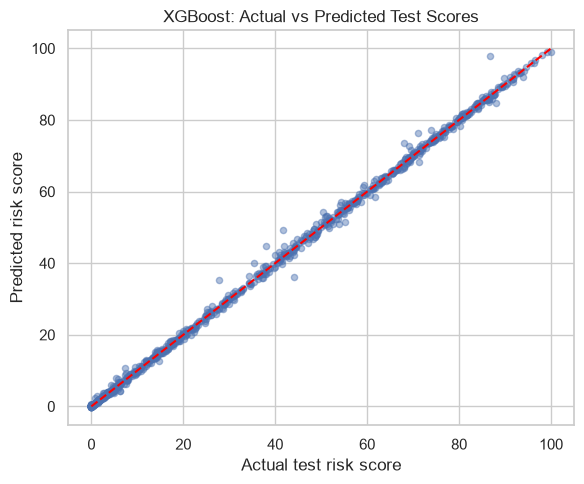

In [6]:
# Check final test results
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)
regression_metrics = {"MAE": float(test_mae), "RMSE": float(test_rmse), "R2": float(test_r2)}
display(pd.DataFrame([regression_metrics], index=["Held-out test"]).round(5))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, test_predictions, alpha=0.45, s=20)
plt.plot([0, 100], [0, 100], color="red", linestyle="--")
plt.xlabel("Actual test risk score")
plt.ylabel("Predicted risk score")
plt.title("XGBoost: Actual vs Predicted Test Scores")
plt.tight_layout()
plt.show()


## 7. Evaluate Risk Levels

Clip a separate copy only for category conversion. Regression metrics above continue to use raw predictions.

Risk-level accuracy: 0.98667
Macro F1: 0.98667
              precision    recall  f1-score   support

     No Risk       0.99      0.99      0.99       225
         Low       0.98      0.97      0.98       225
    Moderate       0.98      0.99      0.99       225
        High       1.00      1.00      1.00       225

    accuracy                           0.99       900
   macro avg       0.99      0.99      0.99       900
weighted avg       0.99      0.99      0.99       900



,No Risk,Low,Moderate,High
No Risk,222,3,0,0
Low,3,219,3,0
Moderate,0,2,223,0
High,0,0,1,224


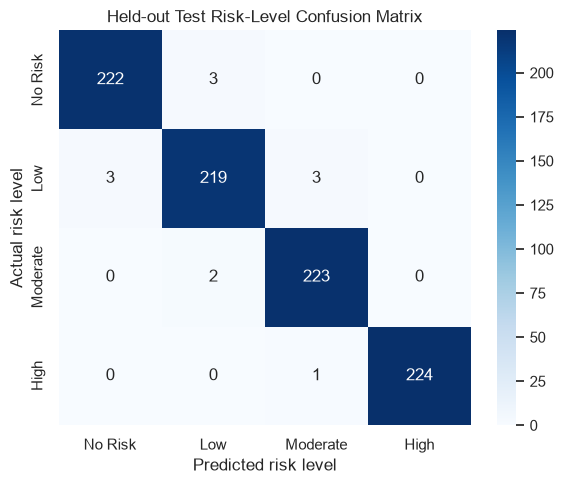

Incorrect category predictions: 12
Adjacent-category errors: 12
Non-adjacent-category errors: 0


In [7]:
# Convert scores into risk levels
risk_labels = ["No Risk", "Low", "Moderate", "High"]
clipped_test_predictions = np.clip(test_predictions.copy(), 0, 100)
predicted_levels = pd.cut(
    clipped_test_predictions,
    bins=[-np.inf, 5, 30, 65, np.inf],
    right=False,
    labels=risk_labels,
)
actual_levels = test_df["risk_level"]
test_accuracy = accuracy_score(actual_levels, predicted_levels)
test_macro_f1 = f1_score(actual_levels, predicted_levels, average="macro")
class_report = classification_report(
    actual_levels, predicted_levels, labels=risk_labels, output_dict=True, zero_division=0
)
print("Risk-level accuracy:", round(test_accuracy, 5))
print("Macro F1:", round(test_macro_f1, 5))
print(classification_report(actual_levels, predicted_levels, labels=risk_labels, zero_division=0))

confusion = confusion_matrix(actual_levels, predicted_levels, labels=risk_labels)
confusion_table = pd.DataFrame(confusion, index=risk_labels, columns=risk_labels)
display(confusion_table)
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_table, annot=True, fmt="d", cmap="Blues")
plt.title("Held-out Test Risk-Level Confusion Matrix")
plt.xlabel("Predicted risk level")
plt.ylabel("Actual risk level")
plt.tight_layout()
plt.show()

wrong_categories = np.asarray(actual_levels.astype(str)) != np.asarray(predicted_levels.astype(str))
wrong_count = int(wrong_categories.sum())
category_positions = {label: index for index, label in enumerate(risk_labels)}
actual_positions = np.array([category_positions[label] for label in actual_levels.astype(str)])
predicted_positions = np.array([category_positions[label] for label in predicted_levels.astype(str)])
adjacent_errors = int((wrong_categories & (np.abs(actual_positions - predicted_positions) == 1)).sum())
non_adjacent_errors = int((wrong_categories & (np.abs(actual_positions - predicted_positions) > 1)).sum())
print("Incorrect category predictions:", wrong_count)
print("Adjacent-category errors:", adjacent_errors)
print("Non-adjacent-category errors:", non_adjacent_errors)


## 8. Review Prediction Errors

Review the confusion matrix and count whether category errors are between neighboring risk levels.

In [8]:
# Summarize category errors
error_summary = pd.DataFrame({
    "Measure": ["Incorrect categories", "Adjacent-category errors", "Non-adjacent-category errors"],
    "Count": [wrong_count, adjacent_errors, non_adjacent_errors],
})
display(error_summary)


,Measure,Count
0,Incorrect categories,12
1,Adjacent-category errors,12
2,Non-adjacent-category errors,0


## 9. Compare with Validation Results

Use saved validation metrics from the selected model metadata. Do not tune or choose another model from test results.

In [9]:
# Compare validation and test
validation_metrics = model_metadata["validation_metrics"]
validation_test_comparison = pd.DataFrame([
    {"Metric": "MAE", "Validation": validation_metrics["mae"], "Test": test_mae},
    {"Metric": "RMSE", "Validation": validation_metrics["rmse"], "Test": test_rmse},
    {"Metric": "R2", "Validation": validation_metrics["r2"], "Test": test_r2},
    {"Metric": "Risk-level accuracy", "Validation": validation_metrics["risk_level_accuracy"], "Test": test_accuracy},
    {"Metric": "Macro F1", "Validation": validation_metrics["risk_level_macro_f1"], "Test": test_macro_f1},
]).set_index("Metric")
display(validation_test_comparison.round(5))


,Validation,Test
Metric,,
MAE,0.50093,0.54835
RMSE,0.76876,1.01473
R2,0.99938,0.99890
Risk-level accuracy,0.98333,0.98667
Macro F1,0.98329,0.98667


## 10. Formula Baseline

Recalculate the original project score using the same coefficients and conditions. This is a synthetic-label baseline, not disease validation.

In [10]:
# Calculate the original synthetic scoring formula
T14 = X_test["mean_temp_previous_14d_c"].to_numpy(dtype=float)
LW14 = X_test["wet_hours_previous_14d"].to_numpy(dtype=float)
C = X_test["consecutive_wetness_hours"].to_numpy(dtype=float)
TempSuit = np.clip(np.where(T14 <= 25, (T14 - 8) / 17, (37.5 - T14) / 12.5), 0, 1)
WetAnchor = np.where((T14 > 21) & (T14 <= 25), 130, 160)
WetSuit = np.clip((LW14 - 30) / (WetAnchor + 45 - 30), 0, 1)
Continuity = np.clip(C / 18, 0, 1)
formula_predictions = np.round(np.clip(100 * TempSuit * (0.88 * WetSuit + 0.12 * Continuity), 0, 100), 3)
formula_mae = mean_absolute_error(y_test, formula_predictions)
formula_rmse = np.sqrt(mean_squared_error(y_test, formula_predictions))
formula_metrics = {"MAE": float(formula_mae), "RMSE": float(formula_rmse)}
display(pd.DataFrame([
    {"Method": "Selected XGBoost", "MAE": test_mae, "RMSE": test_rmse},
    {"Method": "Original formula", "MAE": formula_mae, "RMSE": formula_rmse},
]).set_index("Method").round(6))


,MAE,RMSE
Method,,
Selected XGBoost,0.548347,1.014728
Original formula,0.001060,0.001507


## 11. Final Evaluation Summary

The score formula generated these synthetic targets. Test results assess how well the frozen model imitates that formula, not how well it predicts real plantation infection.

In [11]:
# Save the final evaluation report
report_path = PROJECT_ROOT / "reports" / "yellow_sigatoka" / "final_evaluation" / "Final_Test_Evaluation_Report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)

class_lines = ["| Risk level | Precision | Recall | F1-score | Support |", "|---|---:|---:|---:|---:|"]
for label in risk_labels:
    row = class_report[label]
    class_lines.append(f"| {label} | {row['precision']:.4f} | {row['recall']:.4f} | {row['f1-score']:.4f} | {int(row['support'])} |")
confusion_lines = ["| Actual \\ Predicted | " + " | ".join(risk_labels) + " |", "|---|" + "---:|" * len(risk_labels)]
for label, row in zip(risk_labels, confusion):
    confusion_lines.append("| " + label + " | " + " | ".join(str(int(value)) for value in row) + " |")
comparison_lines = ["| Metric | Validation | Test |", "|---|---:|---:|"]
for metric, row in validation_test_comparison.iterrows():
    comparison_lines.append(f"| {metric} | {row['Validation']:.5f} | {row['Test']:.5f} |")

model_size_mib = model_path.stat().st_size / (1024 ** 2)
report_lines = [
    "# Yellow Sigatoka Final Test Evaluation", "",
    "## Frozen model and data",
    f"- Model: XGBoost {model_metadata['selected_setting']} with {model_metadata['parameters']}.",
    f"- Held-out test size: {len(test_df):,} rows.",
    "- Inputs, in order: `mean_temp_previous_14d_c`, `wet_hours_previous_14d`, `consecutive_wetness_hours`.",
    "- The saved model was loaded; it was not fitted or modified.", "",
    "## Regression results",
    f"- Test MAE: {test_mae:.5f}; RMSE: {test_rmse:.5f}; R2: {test_r2:.5f}.",
    f"- Raw prediction range: {raw_min:.5f} to {raw_max:.5f}; values outside 0 to 100: {out_of_range_count}.", "",
    "## Risk-level results",
    f"- Accuracy: {test_accuracy:.5f}; macro F1: {test_macro_f1:.5f}.",
    *class_lines, "", *confusion_lines, "",
    f"- Incorrect category predictions: {wrong_count}; adjacent-category errors: {adjacent_errors}; non-adjacent-category errors: {non_adjacent_errors}.", "",
    "## Validation and test comparison", *comparison_lines, "",
    f"Test MAE is {(test_mae / validation_metrics['mae'] - 1) * 100:.1f}% higher and RMSE {(test_rmse / validation_metrics['rmse'] - 1) * 100:.1f}% higher than validation, while R2 is lower by {validation_metrics['r2'] - test_r2:.5f}. Risk-level accuracy is {(test_accuracy - validation_metrics['risk_level_accuracy']) * 100:.2f} percentage points higher and macro F1 is {(test_macro_f1 - validation_metrics['risk_level_macro_f1']) * 100:.2f} points higher on test. Overall category performance is similar, but the higher RMSE indicates larger score errors on some test records. Both sets measure imitation of the synthetic scoring target.", "",
    "## Original formula baseline",
    f"- Test formula MAE: {formula_mae:.6f}; RMSE: {formula_rmse:.6f}.",
    "The formula generated the synthetic target, so near-zero formula error is expected. It is not evidence of biological disease prediction.", "",
    "## Deployment considerations",
    f"- Saved XGBoost model size: {model_size_mib:.4f} MiB.",
    f"- Prior validation-set prediction time on this machine: {model_metadata['validation_prediction_time_seconds']:.6f} seconds for 900 rows. This is not a Raspberry Pi benchmark.",
    "- Backend inputs must be validated and the 336-hour features calculated from chronological current and past readings. The simulated scenarios do not show that live IoT sensors are connected.", "",
    "## Limitations and PP1 conclusion",
    "The model predicts a project-defined environmental suitability score, not confirmed disease occurrence. Source NASA weather windows may overlap across simulated scenarios. The frozen model passed this one held-out evaluation and can move to FastAPI integration as a proof of concept, provided the synthetic-label limitation is stated clearly. Real disease claims require measured outcomes and external validation.",
]
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved report:", report_path)
print("Model file unchanged; test evaluation complete.")


Saved report: C:\Users\HP\Desktop\ML training\reports\yellow_sigatoka\final_evaluation\Final_Test_Evaluation_Report.md
Model file unchanged; test evaluation complete.


<>:9: SyntaxWarning: invalid escape sequence '\ '
<>:9: SyntaxWarning: invalid escape sequence '\ '
C:\Users\HP\AppData\Local\Temp\ipykernel_14588\3489535640.py:9: SyntaxWarning: invalid escape sequence '\ '
  confusion_lines = ["| Actual \ Predicted | " + " | ".join(risk_labels) + " |", "|---|" + "---:|" * len(risk_labels)]
